# Project 2: Part 1 and Part 2

## Group members
- Ishan Sapkota
- Sulav Neupane
- Grace Orth
- William Montegomery

# Part 1

# 1. Dataset information

- **Title:** Gun Violence Incidents(2019-2025).
- **Source/Link:** https://doumbiassa.github.io/AI_ML_DS.github.io-/#
- **Context and Purpose:** We choose this dataset because wanted to study gun violence and understand how data can be used to identify patterns. We hear increasing number of gunshots incident around us. So, keeping that in mind we chose this dataset with fictional cities. The dataset, Gun Violence Incidents, contains records dated January 9, 2019, through September 30, 2025. It includes incident locations, incident types, numbers killed and injured, victim age groups, arrest status, and whether incidents were school-related. These variables can be used to examine how recorded incidents and casualties differ across locations and incident types. 

# 2. Basic Data Exploration
- Load the dataset and display the first and last 5 rows. 
- How many rows and columns does your dataset have?  
- What are the column names? 

In [174]:
import pandas as pd

#loading the file
gun_df = pd.read_csv("gun-violence-incidents.csv")


In [175]:
#First five rows
gun_df.head()

,incident_id,date,city,county,incident_type,killed,injured,victim_age_group,suspect_arrested,school_related,source
0,GV702663,2020-11-29,Maple Valley,Ash County,Self-defense,2,three,Adult 18-34,No,No,Police report
1,GV702544,2020-06-03,Maple Valley,Ash County,Unknown,one,2,Adult 35-64,Unknown,No,Police report
2,GV700927,2019-06-17,Riverton,Ash County,Assault,1,2,Adult 18-34,No,No,News report
3,GV702451,08/23/2019,Harbor City,Bay County,Domestic dispute,1,2,Adult 35-64,Yes,No,Hospital record
4,GV702135,2023-11-09,Old Port,Bay County,Domestic dispute,0,1,Teen 12-17,Yes,No,News report


In [176]:
#Last five rows
gun_df.tail()

,incident_id,date,city,county,incident_type,killed,injured,victim_age_group,suspect_arrested,school_related,source
2244,GV700982,05/30/2021,Riverton,Ash County,Drive-by,0,1,Adult 18-34,Unknown,No,Police report
2245,GV702798,04/28/2022,Harbor City,Bay County,Robbery,2,2,Adult 18-34,Unknown,No,Police report
2246,GV702073,2025-08-29,Old Port,Bay County,Robbery,2,0,Adult 18-34,Unknown,No,Police report
2247,GV702058,2023-07-13,Riverton,Ash County,Unknown,0,3,Adult 18-34,No,No,Police report
2248,GV700924,2024-07-04,Summit,Elm County,Self-defense,0,1,Adult 18-34,No,No,Police report


In [177]:
gun_df.shape

(2249, 11)

#### Number of rows: 2249  
#### Number of column: 11

In [178]:
column_names = gun_df.columns.tolist()

In [179]:
print("Column names:")
for i in column_names:
    print(i,",",end=" ")

Column names:
incident_id , date , city , county , incident_type , killed , injured , victim_age_group , suspect_arrested , school_related , source , 

# 3. Data Types and Structure
- Use df.info() to display the data types of each column. 
- Identify: 
    1. Which columns are numerical? 
    2. Which columns are categorical or object type? (use the built-in function to verify this) 
- Do you think any data type should be converted (e.g., object → numeric or datetime)? Explain why. 

In [180]:
gun_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2249 entries, 0 to 2248
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   incident_id       2249 non-null   object
 1   date              2249 non-null   object
 2   city              2249 non-null   object
 3   county            2249 non-null   object
 4   incident_type     2249 non-null   object
 5   killed            2249 non-null   object
 6   injured           2249 non-null   object
 7   victim_age_group  1983 non-null   object
 8   suspect_arrested  2249 non-null   object
 9   school_related    2249 non-null   object
 10  source            2249 non-null   object
dtypes: object(11)
memory usage: 193.4+ KB


**Initially, all 11 columns are object type. No columns are recognised as numerical. So, we have to convert the ones with numbers into numeric data type.
Also, the date are of diffrent formats , so we have to change them to a single format.**

In [181]:
# Converting killed, injured into integer type and date into datetime type.
converted = gun_df.copy()

number_words = {"zero": "0", "one": "1", "two": "2", "three": "3"}

for column in ["killed", "injured"]:
    converted[column] = pd.to_numeric(
        converted[column].replace(number_words),
        errors="raise"
    )

# The file contains both YYYY-MM-DD and MM/DD/YYYY dates
converted["date"] = pd.to_datetime(
    converted["date"], format="mixed", errors="raise"
)

converted.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2249 entries, 0 to 2248
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   incident_id       2249 non-null   object        
 1   date              2249 non-null   datetime64[ns]
 2   city              2249 non-null   object        
 3   county            2249 non-null   object        
 4   incident_type     2249 non-null   object        
 5   killed            2249 non-null   int64         
 6   injured           2249 non-null   int64         
 7   victim_age_group  1983 non-null   object        
 8   suspect_arrested  2249 non-null   object        
 9   school_related    2249 non-null   object        
 10  source            2249 non-null   object        
dtypes: datetime64[ns](1), int64(2), object(8)
memory usage: 193.4+ KB


In [182]:
converted.head()

,incident_id,date,city,county,incident_type,killed,injured,victim_age_group,suspect_arrested,school_related,source
0,GV702663,2020-11-29,Maple Valley,Ash County,Self-defense,2,3,Adult 18-34,No,No,Police report
1,GV702544,2020-06-03,Maple Valley,Ash County,Unknown,1,2,Adult 35-64,Unknown,No,Police report
2,GV700927,2019-06-17,Riverton,Ash County,Assault,1,2,Adult 18-34,No,No,News report
3,GV702451,2019-08-23,Harbor City,Bay County,Domestic dispute,1,2,Adult 35-64,Yes,No,Hospital record
4,GV702135,2023-11-09,Old Port,Bay County,Domestic dispute,0,1,Teen 12-17,Yes,No,News report


# 4. Descriptive Summary
- Get Summary Statistics and interpret at least one column. 
- What do these statistics tell you about the numerical columns (e.g., min, max, mean, std)? 
- Are there any columns where the values seem unusual or inconsistent?

In [183]:
converted.describe()

,date,killed,injured
count,2249,2249.000000,2249.000000
mean,2022-06-08 08:53:59.839928832,0.663851,1.414406
min,2019-01-09 00:00:00,0.000000,0.000000
25%,2020-08-19 00:00:00,0.000000,1.000000
50%,2022-06-09 00:00:00,1.000000,1.000000
75%,2024-04-01 00:00:00,1.000000,2.000000
max,2025-09-30 00:00:00,2.000000,3.000000
std,NaN,0.733620,0.882252


### Interpretation
**killed:** min= 0, max = 2, mean = 0.663851, std = 0.733620. The typical incident killed fewer than one and none of the incidents killed more than two.  
**injured:** min = 0, max = 3, mean = 1.414406, std = 0.882252. Injuries are more common than deaths. On average, incidents injured about 1.41 people. None of the incidents had more than 3 injured people.

### Unusual / Inconsistent Values
- The maximum counts of killed and injured are 2  and 3 respectively. These values are comparatively smaller. Real incidents can have occasionally large casualty, so this dataset look simplified.

# 5. Missing or Duplicate Data
- Check for missing values in each column. 
- Are there any duplicate rows? 
- Provide your observations: Which columns have missing data, and how might that affect analysis? 
- Check for any  other typos, duplicates etc. 

In [184]:
# Checking the number of missing value and its percent
missing  = pd.DataFrame({
    "count" : converted.isna().sum(),
    "percent" : (converted.isnull().mean()*100)
})

In [185]:
missing

,count,percent
incident_id,0,0.000000
date,0,0.000000
city,0,0.000000
county,0,0.000000
incident_type,0,0.000000
killed,0,0.000000
injured,0,0.000000
victim_age_group,266,11.827479
suspect_arrested,0,0.000000
school_related,0,0.000000


In [186]:
#checking number of completely duplicate rows
converted.duplicated().sum()

0

This shows their are no duplicated rows because each entry has a unique incident_id. There could be a duplicate 
hiding behind a different id. Let's check that.

In [187]:
# Checking for duplicate reports excluding incident_id and source
check_duplicates = converted.copy()
check_duplicates["city"] = check_duplicates["city"].replace({"Harbour City": "Harbor City",
                                                            "Harbor city": "Harbor City",
                                                            "Oldport": "Old Port"})
check_duplicates = check_duplicates.drop(["incident_id", "source"], axis = 1)
check_duplicates.duplicated().sum()

90

This shows that there are 90 duplicates row hidden behind different incident_id and source. Let's check the data one by one.

In [188]:
duplicates = check_duplicates[check_duplicates.duplicated(keep=False)]

duplicates.head(50)

,date,city,county,incident_type,killed,injured,victim_age_group,suspect_arrested,school_related
5,2025-03-07,Old Port,Bay County,Robbery,2,3,Adult 18-34,Yes,No
9,2025-08-28,Cedar Park,Elm County,Unknown,1,1,Adult 35-64,No,No
33,2023-05-29,North Shore,Bay County,Robbery,1,1,Adult 35-64,Unknown,No
42,2020-11-04,Riverton,Ash County,Unknown,0,2,NaN,Yes,No
46,2024-06-23,Riverton,Ash County,Domestic dispute,0,1,Adult 18-34,Yes,No
74,2023-11-10,Cedar Park,Elm County,Self-defense,1,2,Adult 35-64,No,No
77,2024-12-18,Harbor City,Bay County,Unknown,1,0,Adult 18-34,Yes,No
79,2019-11-17,North Shore,Bay County,Assault,0,1,Adult 18-34,No,No
82,2020-09-19,North Shore,Bay County,Unknown,1,1,Child 0-11,Yes,No
84,2021-04-10,Harbor City,Bay County,Unknown,0,1,Teen 12-17,Yes,No


We can view different repeated entries.

In [189]:
# Checking if Typos exist
print("--- city ---")
print(converted["city"].value_counts().to_string())


--- city ---
city
Riverton        664
Harbor City     430
Old Port        260
Maple Valley    231
Cedar Park      188
Summit          170
North Shore     149
Lakeview         95
Harbour City     22
Oldport          20
Harbor city      20


### Observations

**Missing Data:** only victim_age_group has missing values. Out of 2249 rows 266 rows have missing victim_age_group. This is about 11.8% of the total dataset, so it in not feasible to drop them. Instead it is better to fill the missing data as "Unknown" because vicitim_age_group is a categorical column, so replacing with mean, median or mode is not suitable.   
**Duplicates:** There are 90 duplicates under different incident_id and sources.  
**Typos:** There are different typos in the names of cities. There are 3 varians of Harbor City i.e. Harbor CIty, Harbour City, Harbor city. There are two variants of Old Port i.e. Old Port and Oldport

### Let's clean the dataset by handling Missing , Duplicates data and data with typos

In [190]:
clean_df = converted.copy()

In [191]:
# Handling typos
clean_df["city"] = clean_df["city"].replace({"Harbour City": "Harbor City",
                                             "Harbor city": "Harbor City",
                                             "Oldport": "Old Port"})

In [192]:
print("--- city ---")
print(clean_df["city"].value_counts().to_string())

--- city ---
city
Riverton        664
Harbor City     472
Old Port        280
Maple Valley    231
Cedar Park      188
Summit          170
North Shore     149
Lakeview         95


In [193]:
# Handling missing values
clean_df["victim_age_group"] = clean_df["victim_age_group"].fillna("Unknown")

In [194]:
# Handling duplicates
clean_df = clean_df.drop_duplicates(subset=[c for c in clean_df.columns if c not in["incident_id", "source"]])
clean_df = clean_df.sort_index()

**Now after the dataset is cleaned**

In [195]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2159 entries, 0 to 2248
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   incident_id       2159 non-null   object        
 1   date              2159 non-null   datetime64[ns]
 2   city              2159 non-null   object        
 3   county            2159 non-null   object        
 4   incident_type     2159 non-null   object        
 5   killed            2159 non-null   int64         
 6   injured           2159 non-null   int64         
 7   victim_age_group  2159 non-null   object        
 8   suspect_arrested  2159 non-null   object        
 9   school_related    2159 non-null   object        
 10  source            2159 non-null   object        
dtypes: datetime64[ns](1), int64(2), object(8)
memory usage: 202.4+ KB


**After cleaning the dataset their are 2159 rows and 11 columns. 2 columns are of integer data type, 1 column is of datetime datatype and 8 columns are of object datatype. We removed 90 duplicate reports by excluding incident_id and source during comparison.**

# 6. Add a New Column Using Existing Columns
- Create a new derived column based on existing data (E.g., BMI = Weight / (Height²). 
- Print the first few rows to confirm the new column has been added. 
- Explain briefly what this new column represents. 

In [217]:
# Calculating the Total people harmed in an incident
clean_df["total_casualties"] = clean_df["killed"] + clean_df["injured"]

# Share of casualties who died (0 = nobody died, 1 = everyone harmed died)
clean_df["fatality_share"] = (clean_df["killed"] / clean_df["total_casualties"]).round(2)

#checking the minimum and maximum number of casualties
print("min casualties:",min(clean_df["total_casualties"]), "\nmax casualties:" ,max(clean_df["total_casualties"]) )

min casualties: 1 
max casualties: 5


In [197]:
clean_df.head()

,incident_id,date,city,county,incident_type,killed,injured,victim_age_group,suspect_arrested,school_related,source,total_casualties,fatality_share
0,GV702663,2020-11-29,Maple Valley,Ash County,Self-defense,2,3,Adult 18-34,No,No,Police report,5,0.40
1,GV702544,2020-06-03,Maple Valley,Ash County,Unknown,1,2,Adult 35-64,Unknown,No,Police report,3,0.33
2,GV700927,2019-06-17,Riverton,Ash County,Assault,1,2,Adult 18-34,No,No,News report,3,0.33
3,GV702451,2019-08-23,Harbor City,Bay County,Domestic dispute,1,2,Adult 35-64,Yes,No,Hospital record,3,0.33
4,GV702135,2023-11-09,Old Port,Bay County,Domestic dispute,0,1,Teen 12-17,Yes,No,News report,1,0.00


### What the new columns represent?
- **total_casualties = killed + injured:** the total number of people harmed, a single measure of how severe an incident was. It ranges from 1 to 5, and every incident in the data has at least one casualty.
- **fatality_share = killed / total_casualties**: of the people harmed, the fraction who died. It separates "many people hurt" from "deadly" incidents.

# 7.Filter the Data 
- Apply at least two different filters to extract subsets of your data. 
- Display the filtered results. 
- Explain what subset you created and why it might be interesting. 

In [198]:
# Filter 1: Incidents with at least one death
fatal_incidents = clean_df[clean_df["killed"] > 0]

display(fatal_incidents.head(5))
print("Number of fatal incidents:", len(fatal_incidents))

,incident_id,date,city,county,incident_type,killed,injured,victim_age_group,suspect_arrested,school_related,source,total_casualties,fatality_share
0,GV702663,2020-11-29,Maple Valley,Ash County,Self-defense,2,3,Adult 18-34,No,No,Police report,5,0.40
1,GV702544,2020-06-03,Maple Valley,Ash County,Unknown,1,2,Adult 35-64,Unknown,No,Police report,3,0.33
2,GV700927,2019-06-17,Riverton,Ash County,Assault,1,2,Adult 18-34,No,No,News report,3,0.33
3,GV702451,2019-08-23,Harbor City,Bay County,Domestic dispute,1,2,Adult 35-64,Yes,No,Hospital record,3,0.33
5,GV900015,2025-03-07,Old Port,Bay County,Robbery,2,3,Adult 18-34,Yes,No,News report,5,0.40


Number of fatal incidents: 1094


In [199]:
# Filter 2: School-related incidents
school_incidents = clean_df[clean_df["school_related"] == "Yes"]

display(school_incidents.head(5))
print("Number of school-related incidents:", len(school_incidents))

,incident_id,date,city,county,incident_type,killed,injured,victim_age_group,suspect_arrested,school_related,source,total_casualties,fatality_share
133,GV700095,2020-10-29,Cedar Park,Elm County,Accidental discharge,0,1,Teen 12-17,No,Yes,Hospital record,1,0.00
143,GV700075,2020-11-23,Cedar Park,Elm County,Unknown,1,3,Teen 12-17,No,Yes,News report,4,0.25
187,GV700615,2023-07-24,Harbor City,Bay County,Assault,0,1,Unknown,No,Yes,News report,1,0.00
211,GV700413,2019-07-17,Harbor City,Bay County,Assault,1,1,Adult 35-64,Yes,Yes,Police report,2,0.50
309,GV700772,2025-04-10,North Shore,Bay County,Unknown,1,1,Adult 35-64,No,Yes,Police report,2,0.50


Number of school-related incidents: 30


**Filter 1: Incidents with at least one death**  
This filter selects incidents where at least one person was killed. 1,094 fatal incidents were found. This subset could help examine which incident types account for the most recorded fatal incidents.

**Filter 2: School-related incidents**  
This filter selects incidents that occurred in a school-related context. This filter returns 30 school-related incidents. This subset could be used to examine their casualty counts and incident types.

# 8. Unique Values and Categories 
- For categorical columns, list the unique values or categories. 
- Which categorical variables seem important for analysis or grouping? 

In [200]:
# calculating number of unique values in the categorical columns
for col in ["city", "county", "incident_type", "victim_age_group", "suspect_arrested", "school_related", "source"]:
    counts = clean_df[col].value_counts()
    print(f"{col}  ({clean_df[col].nunique()} unique)")
    print(counts.to_string())
    print()

city  (8 unique)
city
Riverton        633
Harbor City     456
Old Port        272
Maple Valley    223
Cedar Park      182
Summit          160
North Shore     141
Lakeview         92

county  (4 unique)
county
Bay County     869
Ash County     856
Elm County     342
Pine County     92

incident_type  (7 unique)
incident_type
Assault                 683
Unknown                 379
Domestic dispute        326
Robbery                 260
Drive-by                225
Accidental discharge    151
Self-defense            135

victim_age_group  (6 unique)
victim_age_group
Adult 18-34    948
Adult 35-64    628
Unknown        259
Teen 12-17     188
Senior 65+      91
Child 0-11      45

suspect_arrested  (3 unique)
suspect_arrested
No         1003
Yes         718
Unknown     438

school_related  (2 unique)
school_related
No     2129
Yes      30

source  (3 unique)
source
Police report      1147
News report         808
Hospital record     204



### Categories that seems important for analysis
- **incident_type (7 categories):** It describes what happened and lets us compare severity across kinds of incidents.
- **Cities (8 categories):** It supports geographical comparison

# 9. Grouping and Aggregation 
- Choose at least one categorical column and group the data by that column.  
- Calculate at least one summary measure for a numerical column such as mean, sum, count, 
minimum, or maximum.  
- Display the grouped result.  
- Write 2–3 sentences explaining what you learned from the grouped data.  
- Example: Find the average value of a numerical column for each category in a categorical column. 

In [201]:
by_type = (clean_df.groupby("incident_type", observed=True)
           .agg(incidents=("incident_id", "count"),
                avg_killed=("killed", "mean"),
                avg_injured=("injured", "mean"),
                avg_casualties=("total_casualties", "mean"),
                total_killed=("killed", "sum"))
           .round(2)
           .sort_values("incidents", ascending=False))
by_type

,incidents,avg_killed,avg_injured,avg_casualties,total_killed
incident_type,,,,,
Assault,683,0.68,1.40,2.08,462
Unknown,379,0.63,1.38,2.01,238
Domestic dispute,326,0.70,1.43,2.13,229
Robbery,260,0.73,1.47,2.20,189
Drive-by,225,0.61,1.38,2.00,138
Accidental discharge,151,0.69,1.48,2.17,104
Self-defense,135,0.58,1.36,1.93,78


In [202]:
by_county = (
    clean_df.groupby("county")
    .agg(
        incidents=("incident_id", "count"),
        killed=("killed", "sum"),
        injured=("injured", "sum"),
    )
    .sort_values("incidents", ascending=False)
)
by_county

,incidents,killed,injured
county,,,
Bay County,869,587,1240
Ash County,856,557,1195
Elm County,342,226,480
Pine County,92,68,133


**Group 1: Grouping by Incident Type:**  
After grouping the data by incident type, we can see that assault was the most common type, with 683 incidents and 462 deaths. However, robbery had the highest average number of deaths (0.73) and casualties (2.20) per incident. This shows that although assault incidents were more frequent, robbery incidents had a higher average casualties.

**Group 2: Grouping by county**
After grouping the data by county, we can see that Bay County had the highest number of incidents (869). Bay County also recorded the highest number of deaths (587) and injuries (1,240). This shows that Bay County is affected most by Gun violence incidents.

# 10. Initial Observations 
Write a short paragraph summarizing: 
- What you found interesting about this dataset. 
- Any patterns, issues, or questions that emerged during your initial exploration.


Initially, the dataset had 2249 recorded gun-violence incidents from 2019 through September 2025, but after cleaning the dataset, there are 2159 gun violence incidents across 8 Cities and 4 Counties. Every column was reported as text, so the ones with number had to be converted to integers and datetime datatypes. Also, the date was in different formats, so it had to changed to a single format. The duplicates were hidden under different incident_id and source, so we had to remove those entires. We found 90 duplicate reports, after fixing the city typos.The missing values on victim_age_group were filled as "Unknown" because it a categorical column, so replacing with mean, median or mode is not suitable.

The patterns that emerged are uniform. Even though Assault was the most occured incident, recorded as 683, average killed, casualties and injured per incident across all incident types barely differ. On average, there were about 1.41 injured people per record. In this dataset, there are only maximum 2 killed and 3 injured in an incident. Real incidents can have more casualties. This suggests that the dataset can be simplified.

# Changes on Part 1 before doing Part 2

In the Part 1 submission, we had only found 36 duplicate rows which were hidden under incident_id, but actually there were **90 duplicate rows** which were hidden under incident_id and sources. **Therefore, we detected the duplicates under the sources as well and removed them**. As a result, outcome of some of the operations like average injuries per incident, school-related incidents and assault incidents changed. **These changes have been updated on their respective markdown cells as well.**

# Part 2

In [216]:
#importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# SECTION I: INDIVIDUAL, COMPARATIVE AND GROUPED VISUALIZATIONS


# 1. Create at least two of the following: 
- A histogram or boxplot for a numerical column (e.g., income, score, age, etc.). 
- A bar chart for a categorical column (e.g., region, department, gender, etc.). 
- A count plot showing frequency distribution of a key variable.   
Explain: What does this visualization reveal about the distribution or spread of 
values? 

## Distribution of Total Casualties per Incident

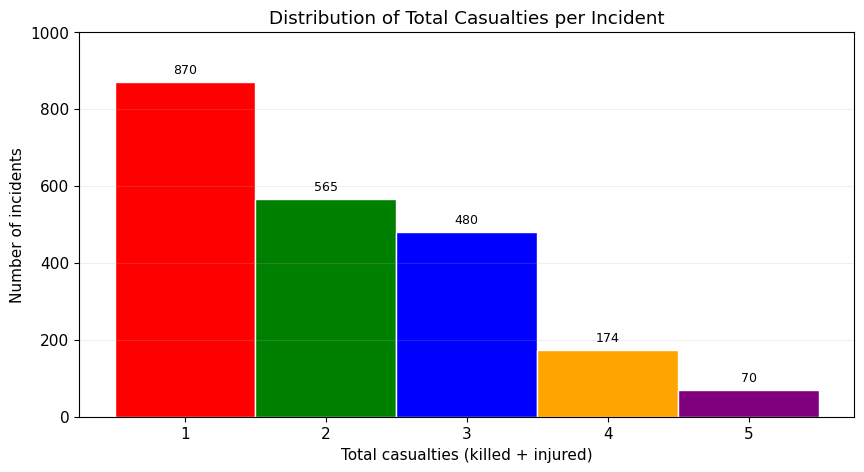

In [204]:
fig, ax = plt.subplots()
counts = clean_df["total_casualties"].value_counts()
ax.hist(clean_df["total_casualties"], bins = np.arange(0.5,6.5,1), edgecolor = "white" )

colors = ["red", "green", "blue", "orange", "purple"]
for i in range(len(ax.patches)):
    ax.patches[i].set_facecolor(colors[i])

for x, y in zip(counts.index, counts.values):
  ax.text(x, y + 15, str(y), ha="center",va="bottom", fontsize=9    
  )


plt.title("Distribution of Total Casualties per Incident")
plt.xlabel("Total casualties (killed + injured)")
plt.ylabel("Number of incidents")
plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, max(counts) * 1.15)
plt.grid(axis="y", alpha=0.2)
plt.show()

**Interpretation:**   
The histogram shows that majority of incidents involved had fewer casualties. There were 870 incidents with only 1 casualty, which is the highest frequency. As the number of casualties increases, the number of incidents generally decreases. Only 70 incidents had 5 casualties.


## Number of Incidents by Type

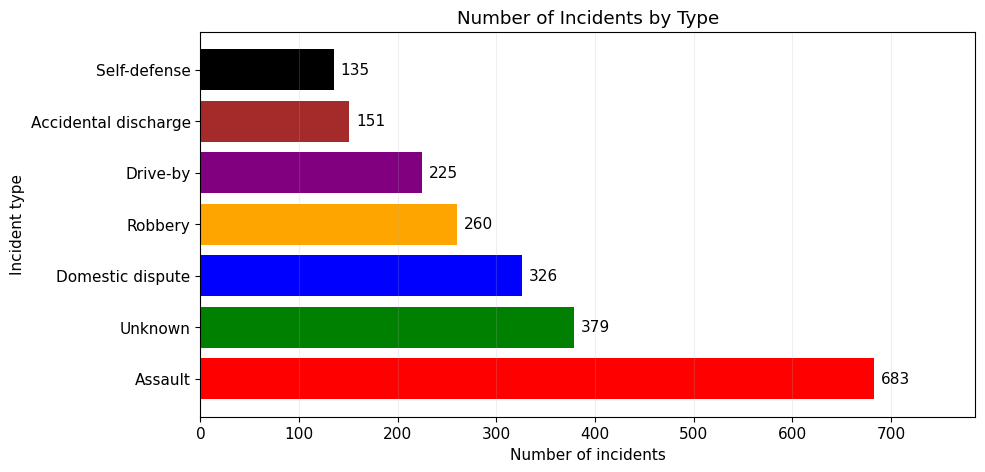

In [205]:
incident_counts = clean_df["incident_type"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(incident_counts.index, incident_counts.values)

colors = ["red", "green", "blue", "orange", "purple", "brown","black"]

for i in range(len(ax.patches)):
    ax.patches[i].set_facecolor(colors[i])

ax.bar_label(bars, padding=5)

plt.title("Number of Incidents by Type")
plt.xlabel("Number of incidents")
plt.ylabel("Incident type")
plt.xlim(0, incident_counts.max()*1.15)
plt.grid(axis="x", alpha=0.2)
plt.show()

**Interpretations:**  
The bar chart shows that Assault was the most common incident type, with 683 incidents, followed by Unknown with 379 incidents and Domestic dispute with 326 incidents. Self-defense was the least common, with 135 incidents. This shows that the number of incidents varies depending on the incident type.

## Distribution of Total Casualties per Incident

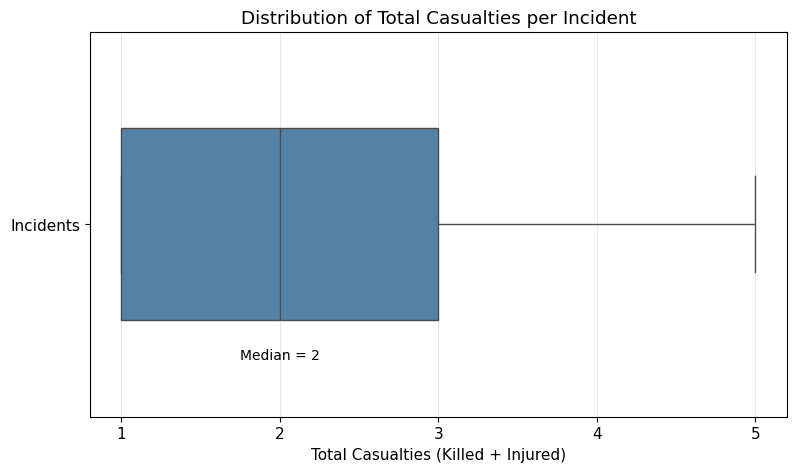

In [224]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=clean_df,
    x="total_casualties",
    color="steelblue",
    width = 0.5,
    ax=ax
)

plt.title("Distribution of Total Casualties per Incident")
plt.xlabel("Total Casualties (Killed + Injured)")

plt.xticks([1, 2, 3, 4, 5])
plt.yticks([0], ["Incidents"])
plt.grid(axis="x", alpha=0.3)
ax.text(2, 0.35, "Median = 2", ha="center", fontsize=10)

plt.show()



**Interpretations:**  
The boxplot shows that the median number of casualties per incident was 2. Most incidents had casualties between 1 and 3, while the maximum was 5. There were no outliers in the dataset. This shows that the number of casualties per incident was generally low, with limited variation.

## Number of Incidents by Victim Age Group

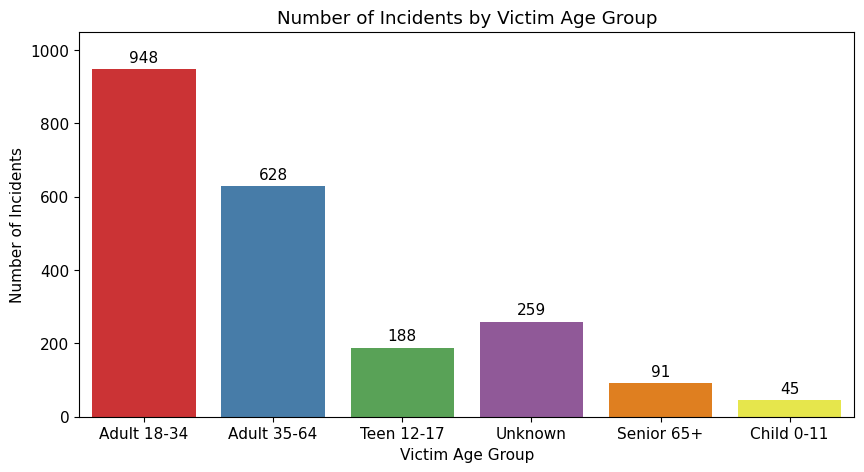

In [207]:
plt.figure(figsize=(10, 5))

ax = sns.countplot(data=clean_df, 
    x="victim_age_group",
    hue="victim_age_group",
    palette="Set1",
    legend=False)

for container in ax.containers:
    ax.bar_label(container, padding=3)


plt.title("Number of Incidents by Victim Age Group")
plt.xlabel("Victim Age Group")
plt.ylabel("Number of Incidents")
ax.set_ylim(0,1050)
plt.show()

**Interpretations:**  
The count plot shows that the 18–34 age group had the highest number of incidents(948) followed by the 35–64 age group with 628 incidents. Children aged 0–11 had the lowest count with only 45 incidents. This shows that incidents were recorded more frequently under young adult age groups in this dataset. Also, 259 incidents had an unknown victim age group.

## Incidents, Deaths, and Injuries by County

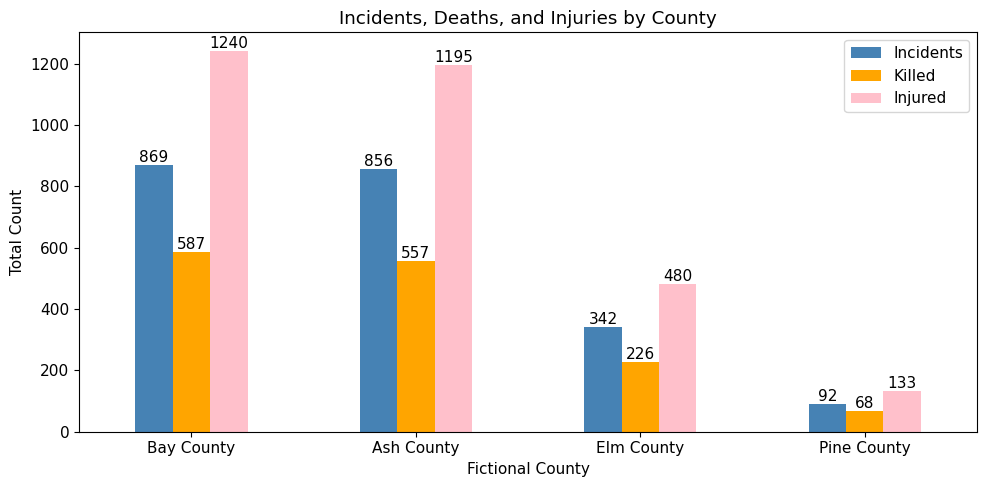

In [208]:

ax = by_county[["incidents", "killed", "injured"]].plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "orange", "pink"]
)

plt.title("Incidents, Deaths, and Injuries by County")
plt.xlabel("Fictional County")
plt.ylabel("Total Count")
plt.xticks(rotation=0)
plt.legend(["Incidents", "Killed", "Injured"])

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()



**Interpretations:**  
The grouped bar chart shows that Bay County recorded the highest number of incidents (869), deaths (587), and injuries (1,240). Pine County had the lowest number of incidents (92), deaths (68), and injuries (133). In every county, injuries were higher than deaths. This shows that the recorded incidents and casualties were not distributed equally among the four counties.


# SECTION II: RELATIONSHIP VISUALIZATIONS
Use visualizations that reveal relationships between two numerical or mixed variables: 
- A scatter plot. 
- A heatmap of correlations (you can use seaborn). 
Explain: Do you observe trends, correlations, or outliers?

## Average Killed vs Average Injured by Incident Type

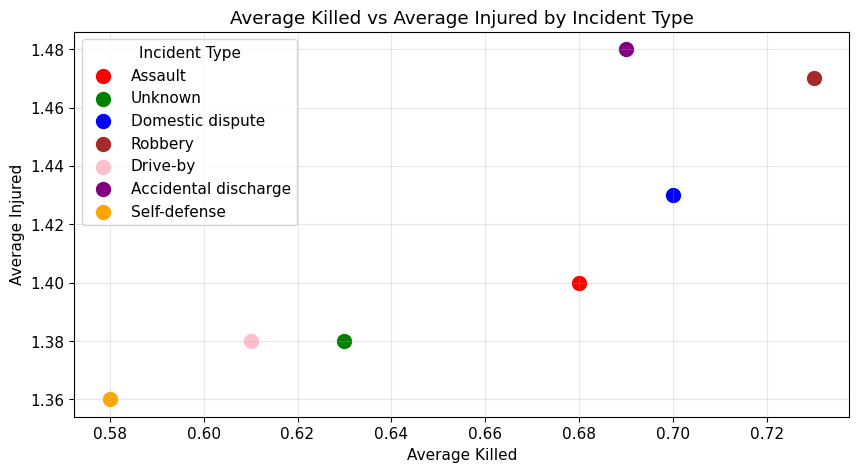

In [209]:
plt.figure(figsize=(10, 5))

colors = ["red", "green", "blue", "brown", "pink", "purple", "orange"]

for i in range(len(by_type)):
    plt.scatter(by_type["avg_killed"].iloc[i],
                by_type["avg_injured"].iloc[i],
                color=colors[i],
                label=by_type.index[i],
                s=100)

plt.title("Average Killed vs Average Injured by Incident Type")
plt.xlabel("Average Killed")
plt.ylabel("Average Injured")
plt.legend(title="Incident Type")
plt.grid(alpha=0.3)
plt.show()

**Interpretations:**  
The scatter plot displays the average number of people killed and injured for different incident types. Robbery had the highest average number of people killed, whereas accidental discharge had the highest average number of people injured. Self-defense had the lowest average number of people killed and injured.

## Correlation Between Killed, Injured, and Total Casualties

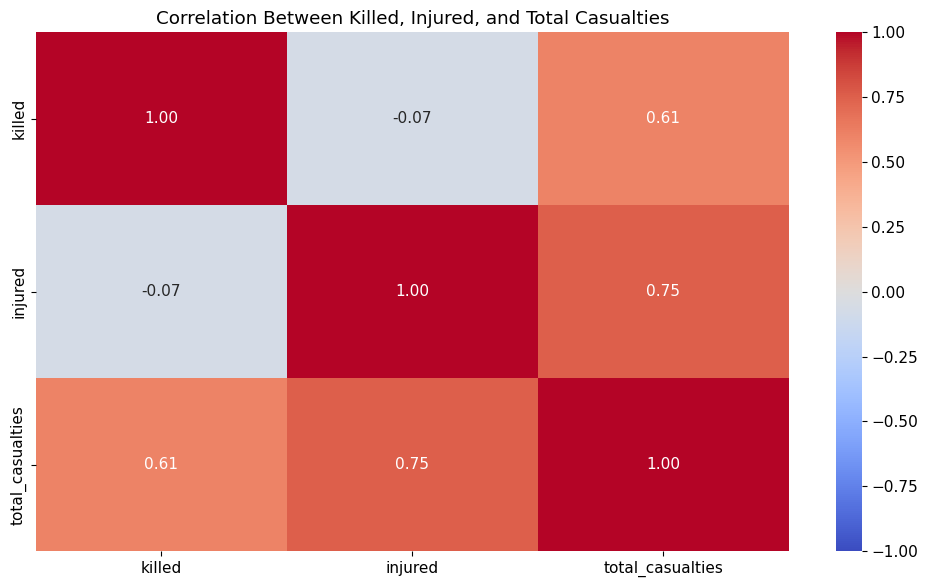

In [210]:


plt.figure(figsize=(10, 6))

sns.heatmap(
    clean_df[["killed", "injured", "total_casualties"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Killed, Injured, and Total Casualties")
plt.tight_layout()
plt.show()


**Interpretations:**  
The heatmap shows the relationship between the number of people killed, injured, and total casualties.
- **Killed and Injured (-0.07):** A slight negative correlation is present. There is almost no linear relationship between the number of people killed and injured in an incident.
- **Killed and Total Casualties (0.61):** There exits a moderately strong positive correlation. The incidents with more deaths generally have greater number of casualties.
- **Injured and Total Casualties (0.75):** There is a strong positive correlation. The incidents with higher number of injuries generally have more total casualties.

## Number of Incidents by Year (2025 is incomplete)

In [211]:
by_year = clean_df.groupby(clean_df["date"].dt.year).size()

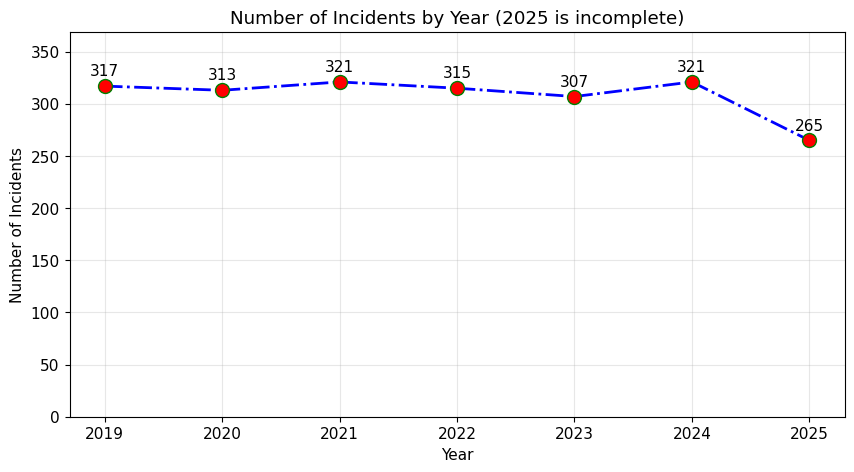

In [231]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(by_year.index, by_year.values,
       color = "blue", marker = "o",linewidth = 2, markersize = 10,markerfacecolor = 'red',ls= "-.",
        markeredgecolor = "green")


for x, y in zip(by_year.index, by_year.values):
    ax.text(x, y + 10, str(y), ha="center")

plt.ylim(0, by_year.max() * 1.15)

plt.title("Number of Incidents by Year (2025 is incomplete)")
plt.xlabel("Year")
plt.ylabel("Number of Incidents")

ax.grid(alpha=0.3)

**Interpretations:**  
The line plot show that the number of incidents is similar from 2019 to 2024 . 2025 saw a significant fall because the data for that year is incomplete.

## Number of Incidents by Season (2020–2024)

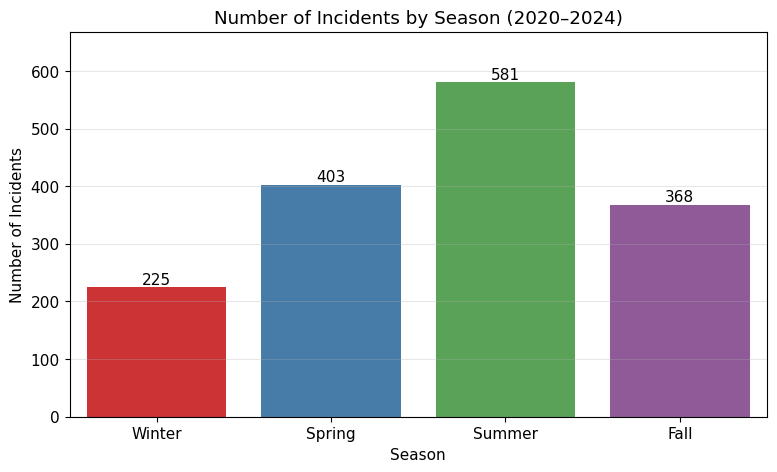

In [213]:

clean_df["date"] = pd.to_datetime(clean_df["date"])

by_month = clean_df[
    clean_df["date"].dt.year.between(2020, 2024)
].groupby(clean_df["date"].dt.month).size()


seasons = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
}

clean_df["season"] = clean_df["date"].dt.month.map(seasons)

by_season = clean_df[
    clean_df["date"].dt.year.between(2020, 2024)]["season"].value_counts().reindex(
    ["Winter", "Spring", "Summer", "Fall"]
)


plt.figure(figsize=(9, 5))

ax = sns.barplot(x=by_season.index, y=by_season.values,
                 palette = "Set1", hue=by_season.index)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Number of Incidents by Season (2020–2024)")
plt.xlabel("Season")
plt.ylabel("Number of Incidents")
plt.ylim(0, by_season.max() * 1.15)
plt.grid(axis="y", alpha=0.3)

plt.show()


**Interpretations:**  
The bar graph shows that summer had highest number of incidents(581) over the 5 year period from 2020 to 2024, and winter had lowest number of incidents (225) which is more than half than that of summer. Spring and Fall were in between with 403 and 368 incidents respectively. We didn't use the data of 2019 and 2025 here because it is incomplete. Overall, the graph shows that the number of incidents were higher during the warmer month.

## Number of Incidents by Month (2020–2024)

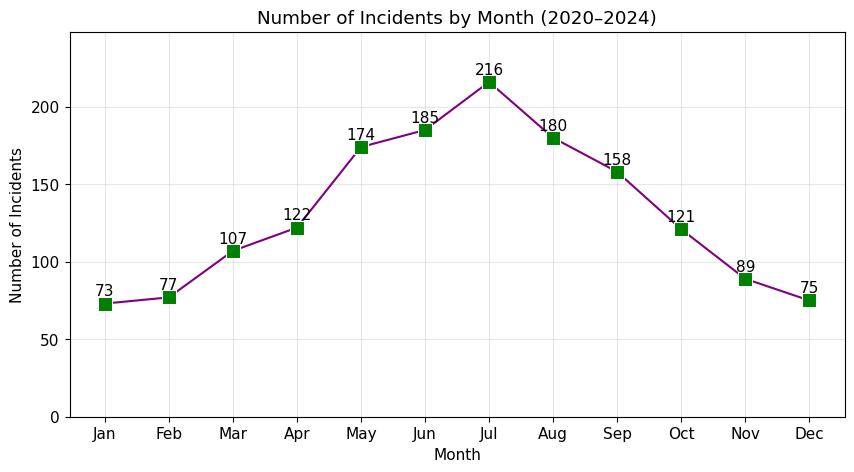

In [214]:

plt.figure(figsize=(10, 5))

sns.lineplot(x=by_month.index, y=by_month.values,
             marker="s", color="purple", markersize = 10,markerfacecolor = 'green')

plt.title("Number of Incidents by Month (2020–2024)")
plt.xlabel("Month")
plt.ylabel("Number of Incidents")
plt.xticks(range(1, 13),
           ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

for x, y in zip(by_month.index, by_month.values):
    plt.text(x, y + 5, str(y), ha="center")

plt.ylim(0, by_month.max() * 1.15)
plt.grid(alpha=0.3)
plt.show()


**Interpretations:**  
This graph supports the result of the seasonal barplot that the number of incidents were higher during the warmer month. July had the highest number of incidents (216), while January had the lowest (73). The number of incidents generally increased from January to July and then started decreasing toward December. We didn't use the data of 2019 and 2025 here because it is incomplete.



## Distribution of Total Casualties by Incident Type

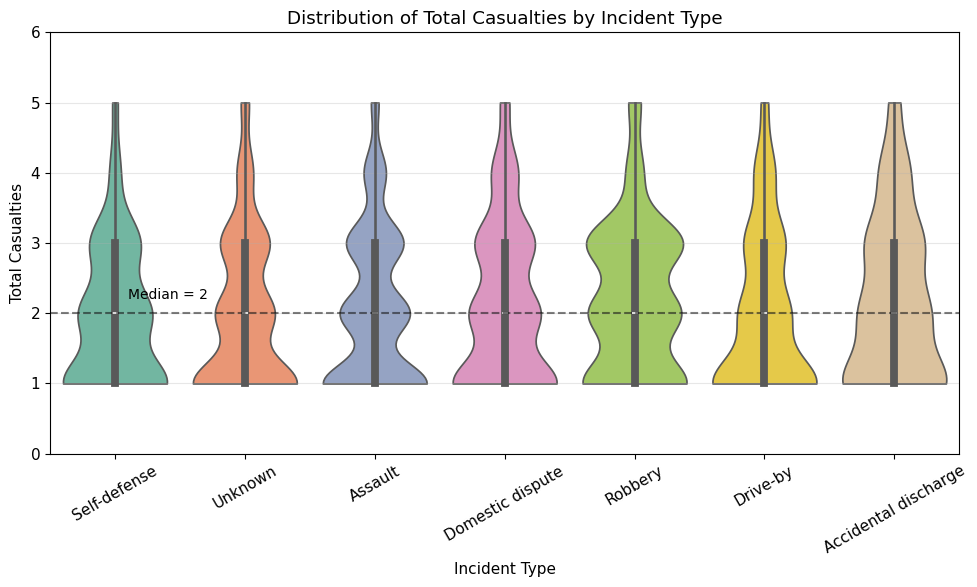

In [234]:

plt.figure(figsize=(10,6))

sns.violinplot(
    data=clean_df,
    x="incident_type",
    y="total_casualties",
    hue="incident_type",
    palette="Set2",
    legend=False,
    inner="box",
    cut=0
)

plt.axhline(y=2, color="black", linestyle="--", alpha=0.5)
plt.text(0.1, 2.2, "Median = 2", fontsize=10)
plt.title("Distribution of Total Casualties by Incident Type")
plt.xlabel("Incident Type")
plt.ylabel("Total Casualties")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.ylim(0,6)
plt.tight_layout()
plt.show()


**Interpretations:**  
The violin plot shows the distribution of total casualties across different incident types. Median number of casualties for each incident was 2, and the range of number of casualties was from 1 to 5. This shows that the distribution of casualties did not differ much across incident types.

# Summary and Conclusion
In this part of project, we analyzed fictional gun violence dataset covering dates from January, 2019 to September, 2025. We used different graphs to understand the patterns in the data. 

Using the visualization graphs we found that Assault was the most common incident type type with 683 incidents, but Robbery had the highest average number of people killed, while accidental discharge had the highest average number of people injured. The boxplot and violin plot showed us that 2 was the median number of casualties per incident. 

We also examined how the number of incidents changed over the seasons of 2020-2024. Summer had the highest number of incidents and winter had the least. The heatmap showed that there is almost no correlation between number of people killed and injured in individual incidents. 

To do this project part of the project, we used our code of Part1 where we had clean our data and performed operations like grouping which were relevant to the part 2. For the part 2 we used both matplotlib and seaborn according to our choice.

Overall, this project helped us understand how to clean data, create graphs, and find patterns in a dataset. We also learned that cleaning the data is important because missing values, duplicates, and typos can affect the results.

### What did we learn?
1. **Data Quality Matters:** Mixed formats, inconsistent city names, missing values and duplicate reports change results unless we clean them first.
2. **Charts answer different questions:** Histograms show distributions; grouped bar compare totals; scatter plots compare averages; lines show changes over time.

In [235]:
clean_df.to_csv("cleaned_gun_violence.csv", index=False)